# Week 11 — Clustering II: DBSCAN and Hierarchical Agglomerative Clustering

**Project:** Predicting Loan Repayment Risk Using LendingClub Data

Week 10's K-Means assumes compact, roughly spherical clusters and puts every loan in one. This week tests two methods with different assumptions on the **same borrower features and scaling**:

* **DBSCAN** finds clusters as dense regions and labels loans in sparse regions as **noise** (Ester et al., 1996). It needs no k, but needs a density threshold (`eps`, `min_samples`).
* **Hierarchical agglomerative clustering (HAC)** starts with every loan as its own cluster and repeatedly merges the closest pair. The **linkage** defines "closest" (Ward, complete, average, single); the **dendrogram** records every merge, and cutting it at a height gives clusters.

Questions:
1. Do borrowers form dense, separated groups (DBSCAN), or a continuum?
2. Are DBSCAN's noise loans riskier than typical loans?
3. Which linkage gives usable segments, and do they agree with Week 10's K-Means?

**Scale.** Both methods need pairwise distances (HAC stores all n²/2 of them), so they are run on random samples of training loans: 20,000 for DBSCAN and 5,000 for HAC.

## 0. Setup

In [1]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)
sns.set_theme(style="whitegrid", font="serif")
pd.set_option("display.float_format", "{:,.4f}".format)
print("scikit-learn", sklearn.__version__)

DATA = Path("data/lc_model_sample.parquet")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
DB_N, HAC_N = 20_000, 5_000
FEATS = ["log_annual_inc", "dti", "fico", "revol_util", "log_revol_bal", "open_acc", "total_acc",
         "credit_hist_years", "emp_length_yrs", "mort_acc", "inq_last_6mths", "loan_amnt"]   # same as Week 10

scikit-learn 1.9.1


In [2]:
df = pd.read_parquet(DATA)
df[FEATS] = df[FEATS].astype(float)
train = df[df.split == "train"].reset_index(drop=True)
imp = SimpleImputer(strategy="median").fit(train[FEATS])
scaler = StandardScaler().fit(imp.transform(train[FEATS]))
Z = scaler.transform(imp.transform(train[FEATS]))
y = train["target"].astype(int).values

# Week 10's K-Means, refit with the same settings for comparison
w10 = pd.read_csv(RES_DIR / "week10_summary.csv", index_col=0).iloc[:, 0]
K = int(float(w10["k"]))
km = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit(Z)
rng = np.random.default_rng(RANDOM_STATE)
db_idx = rng.choice(len(Z), DB_N, replace=False)
hac_idx = db_idx[:HAC_N]          # HAC sample is a subset of the DBSCAN sample
print(f"training loans {len(Z):,} | DBSCAN sample {DB_N:,} | HAC sample {HAC_N:,} | Week 10 k = {K}")

training loans 140,000 | DBSCAN sample 20,000 | HAC sample 5,000 | Week 10 k = 2


## 1. DBSCAN: choosing `min_samples` and `eps`

* `min_samples` — how many loans (including itself) must lie within `eps` for a loan to be a **core** point. A common rule is 2 × the number of dimensions: 2 × 12 = 24.
* `eps` — the neighborhood radius. The **k-distance plot** sorts every loan's distance to its `min_samples`-th neighbor; dense-region loans have small values and outliers large ones, and the "knee" where the curve turns upward is the usual choice (Ester et al., 1996; Schubert et al., 2017).

The knee is located as the point farthest from the straight line joining the ends of the sorted curve.

In [3]:
MIN_SAMPLES = 2 * len(FEATS)
Zd = Z[db_idx]
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Zd).kneighbors(Zd)[0][:, -1])
xn = np.linspace(0, 1, len(kdist)); yn = (kdist - kdist.min()) / (kdist.max() - kdist.min())
KNEE_EPS = float(kdist[np.argmax(xn - yn)])        # max distance below the chord (convex curve)
print(f"min_samples = {MIN_SAMPLES} | knee eps = {KNEE_EPS:.3f} | k-distance percentiles 50/90/99: {np.percentile(kdist, [50, 90, 99]).round(2)}")

min_samples = 24 | knee eps = 2.743 | k-distance percentiles 50/90/99: [1.81 2.52 3.64]


In [4]:
db_rows, db_labels = [], {}
for q in [50, 70, 80, 90, 95, 98]:
    eps = float(np.percentile(kdist, q))
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES, n_jobs=-1).fit_predict(Zd)
    db_labels[q] = lab
    n_cl = len(set(lab) - {-1}); clustered = lab != -1
    sizes = pd.Series(lab[clustered]).value_counts()
    sil = silhouette_score(Zd[clustered][:10_000], lab[clustered][:10_000]) if n_cl >= 2 else np.nan
    db_rows.append({"eps percentile": q, "eps": eps, "clusters": n_cl, "noise share": 1 - clustered.mean(),
                    "largest cluster share": sizes.max() / len(lab) if n_cl else 0, "silhouette (non-noise)": sil,
                    "charge-off: noise": y[db_idx][~clustered].mean() if (~clustered).any() else np.nan,
                    "charge-off: clustered": y[db_idx][clustered].mean() if clustered.any() else np.nan})
db_tab = pd.DataFrame(db_rows).set_index("eps percentile"); db_tab

,eps,clusters,noise share,largest cluster share,silhouette (non-noise),charge-off: noise,charge-off: clustered
eps percentile,,,,,,,
50,1.8124,1,0.2212,0.7788,NaN,0.1462,0.1464
70,2.0488,1,0.1030,0.8970,NaN,0.1519,0.1457
80,2.2143,1,0.0616,0.9384,NaN,0.1461,0.1464
90,2.5202,1,0.0262,0.9738,NaN,0.1702,0.1457
95,2.8315,1,0.0130,0.9870,NaN,0.1654,0.1461
98,3.2646,1,0.0041,0.9959,NaN,0.1928,0.1462


In [5]:
# Main DBSCAN run at the knee eps
db = DBSCAN(eps=KNEE_EPS, min_samples=MIN_SAMPLES, n_jobs=-1).fit(Zd)
lab = db.labels_; noise = lab == -1
n_clusters = len(set(lab) - {-1})
sizes = pd.Series(lab[~noise]).value_counts()
print(f"eps = {KNEE_EPS:.3f}: {n_clusters} cluster(s), noise {noise.mean():.1%}, largest cluster {sizes.max()/len(lab) if n_clusters else 0:.1%} of loans")
rate_noise, rate_core = y[db_idx][noise].mean(), y[db_idx][~noise].mean()
se = np.sqrt(rate_core * (1 - rate_core) / max(noise.sum(), 1))
print(f"Charge-off: noise {rate_noise:.2%} (n = {noise.sum():,}) vs clustered {rate_core:.2%} (n = {(~noise).sum():,}); z = {(rate_noise - rate_core) / se:.1f}")

eps = 2.743: 1 cluster(s), noise 1.5%, largest cluster 98.5% of loans
Charge-off: noise 17.45% (n = 298) vs clustered 14.59% (n = 19,702); z = 1.4


In [6]:
# What makes a loan "noise"? Median standardized feature values, noise vs clustered
noise_prof = pd.DataFrame({"noise (median z)": np.median(Zd[noise], 0) if noise.any() else np.nan,
                           "clustered (median z)": np.median(Zd[~noise], 0),
                           "noise: share |z| > 2": (np.abs(Zd[noise]) > 2).mean(0) if noise.any() else np.nan,
                           "clustered: share |z| > 2": (np.abs(Zd[~noise]) > 2).mean(0)}, index=FEATS)
noise_prof.sort_values("noise: share |z| > 2", ascending=False)

,noise (median z),clustered (median z),noise: share |z| > 2,clustered: share |z| > 2
log_revol_bal,-0.9058,0.1019,0.4933,0.0266
revol_util,-1.7378,0.0666,0.4094,0.0190
inq_last_6mths,0.2817,-0.7064,0.3389,0.0593
fico,0.6257,-0.1761,0.2953,0.0499
total_acc,0.7982,-0.1382,0.2953,0.0345
log_annual_inc,0.9602,-0.0085,0.2685,0.0436
mort_acc,0.1924,-0.3099,0.2450,0.0504
open_acc,-0.2391,-0.2391,0.2282,0.0410
credit_hist_years,0.3135,-0.1853,0.1711,0.0433
loan_amnt,0.0529,-0.2587,0.1510,0.0549


## 2. Hierarchical agglomerative clustering: linkage methods

* **Ward** merges the pair of clusters whose union least increases within-cluster variance — the same objective as K-Means, so it tends to give balanced, compact clusters (Euclidean only).
* **Complete** uses the *farthest* pair of points between two clusters; **average** the mean pairwise distance; **single** the *closest* pair, which can "chain" through a continuum and produce one giant cluster.

Each dendrogram is cut into K clusters (Week 10's k). Cophenetic correlation measures how faithfully the dendrogram's merge heights preserve the original pairwise distances (1 = perfectly). Agreement with K-Means uses the adjusted Rand index (ARI) on the same 5,000 loans.

In [7]:
Zh = Z[hac_idx]; yh = y[hac_idx]; km_h = km.labels_[hac_idx]
D = {m: pdist(Zh, metric=m) for m in ["euclidean", "cityblock", "cosine"]}
hac_rows, hac_labels, links = [], {}, {}
for method, metric in [("ward", "euclidean"), ("complete", "euclidean"), ("average", "euclidean"), ("single", "euclidean"),
                       ("average", "cityblock"), ("average", "cosine")]:
    t0 = time.time()
    L = linkage(Zh, method="ward") if method == "ward" else linkage(D[metric], method=method)
    links[(method, metric)] = L
    lab_h = fcluster(L, K, criterion="maxclust") - 1
    hac_labels[(method, metric)] = lab_h
    sizes_h = np.bincount(lab_h)
    hac_rows.append({"linkage": method, "metric": "manhattan" if metric == "cityblock" else metric,
                     "cophenetic corr.": cophenet(L, D[metric])[0],
                     "largest cluster share": sizes_h.max() / len(lab_h), "clusters with < 1% of loans": int((sizes_h < 0.01 * len(lab_h)).sum()),
                     "silhouette": silhouette_score(Zh, lab_h) if len(set(lab_h)) > 1 else np.nan,
                     "ARI vs K-Means": adjusted_rand_score(km_h, lab_h),
                     "charge-off range across clusters": pd.Series(yh).groupby(lab_h).mean().max() - pd.Series(yh).groupby(lab_h).mean().min(),
                     "seconds": time.time() - t0})
hac_tab = pd.DataFrame(hac_rows).set_index(["linkage", "metric"]); hac_tab

cophenetic corr.  largest cluster share  \
linkage  metric                                               
ward     euclidean            0.3114                 0.6256   
complete euclidean            0.4349                 0.9894   
average  euclidean            0.6754                 0.9994   
single   euclidean            0.6854                 0.9998   
average  manhattan            0.6089                 0.9994   
         cosine               0.4556                 0.5980   

                    clusters with < 1% of loans  silhouette  ARI vs K-Means  \
linkage  metric                                                               
ward     euclidean                            0      0.1204          0.4039   
complete euclidean                            0      0.3423          0.0057   
average  euclidean                            1      0.5507          0.0003   
single   euclidean                            1      0.5410          0.0001   
average  manhattan                            1      0.5507          0.0003   
         cosine                               0      0.1201          0.4599   

                    charge-off range across clusters  seconds  
linkage  metric                                                
ward     euclidean                            0.0049   1.3006  
complete euclidean                            0.0110   1.0847  
average  euclidean                            0.1431   1.4036  
single   euclidean                            0.1430   0.6967  
average  manhattan                            0.1431   1.5798  
         cosine                               0.0420   1.0446

In [8]:
# Ward clusters: profile and charge-off, matched to K-Means clusters
ward = hac_labels[("ward", "euclidean")]
ward_prof = pd.DataFrame(Zh, columns=FEATS).groupby(ward).median()
ward_prof.insert(0, "share", np.bincount(ward) / len(ward))
ward_prof["charge-off"] = pd.Series(yh).groupby(ward).mean()
ward_prof["n"] = np.bincount(ward)
ward_prof["most common K-Means cluster"] = pd.Series(km_h).groupby(ward).agg(lambda s: s.value_counts().index[0])
ward_prof["share in that K-Means cluster"] = pd.Series(km_h).groupby(ward).agg(lambda s: s.value_counts(normalize=True).iloc[0])
ward_prof.sort_values("charge-off")

,share,log_annual_inc,dti,fico,revol_util,log_revol_bal,open_acc,total_acc,credit_hist_years,emp_length_yrs,mort_acc,inq_last_6mths,loan_amnt,charge-off,n,most common K-Means cluster,share in that K-Means cluster
0,0.3744,0.4370,0.1683,-0.1761,0.2170,0.5264,0.3391,0.5429,0.3022,0.8756,0.1924,0.2817,0.2399,0.1400,1872,0,0.8488
1,0.6256,-0.2969,-0.1894,-0.1761,-0.0587,-0.1002,-0.4319,-0.4787,-0.4288,-0.2490,-0.8122,-0.7064,-0.3834,0.1448,3128,1,0.7996


In [9]:
pd.crosstab(pd.Series(ward, name="Ward cluster"), pd.Series(km_h, name="K-Means cluster"), normalize="index").round(2)

K-Means cluster,0,1
Ward cluster,,
0,0.8500,0.1500
1,0.2000,0.8000


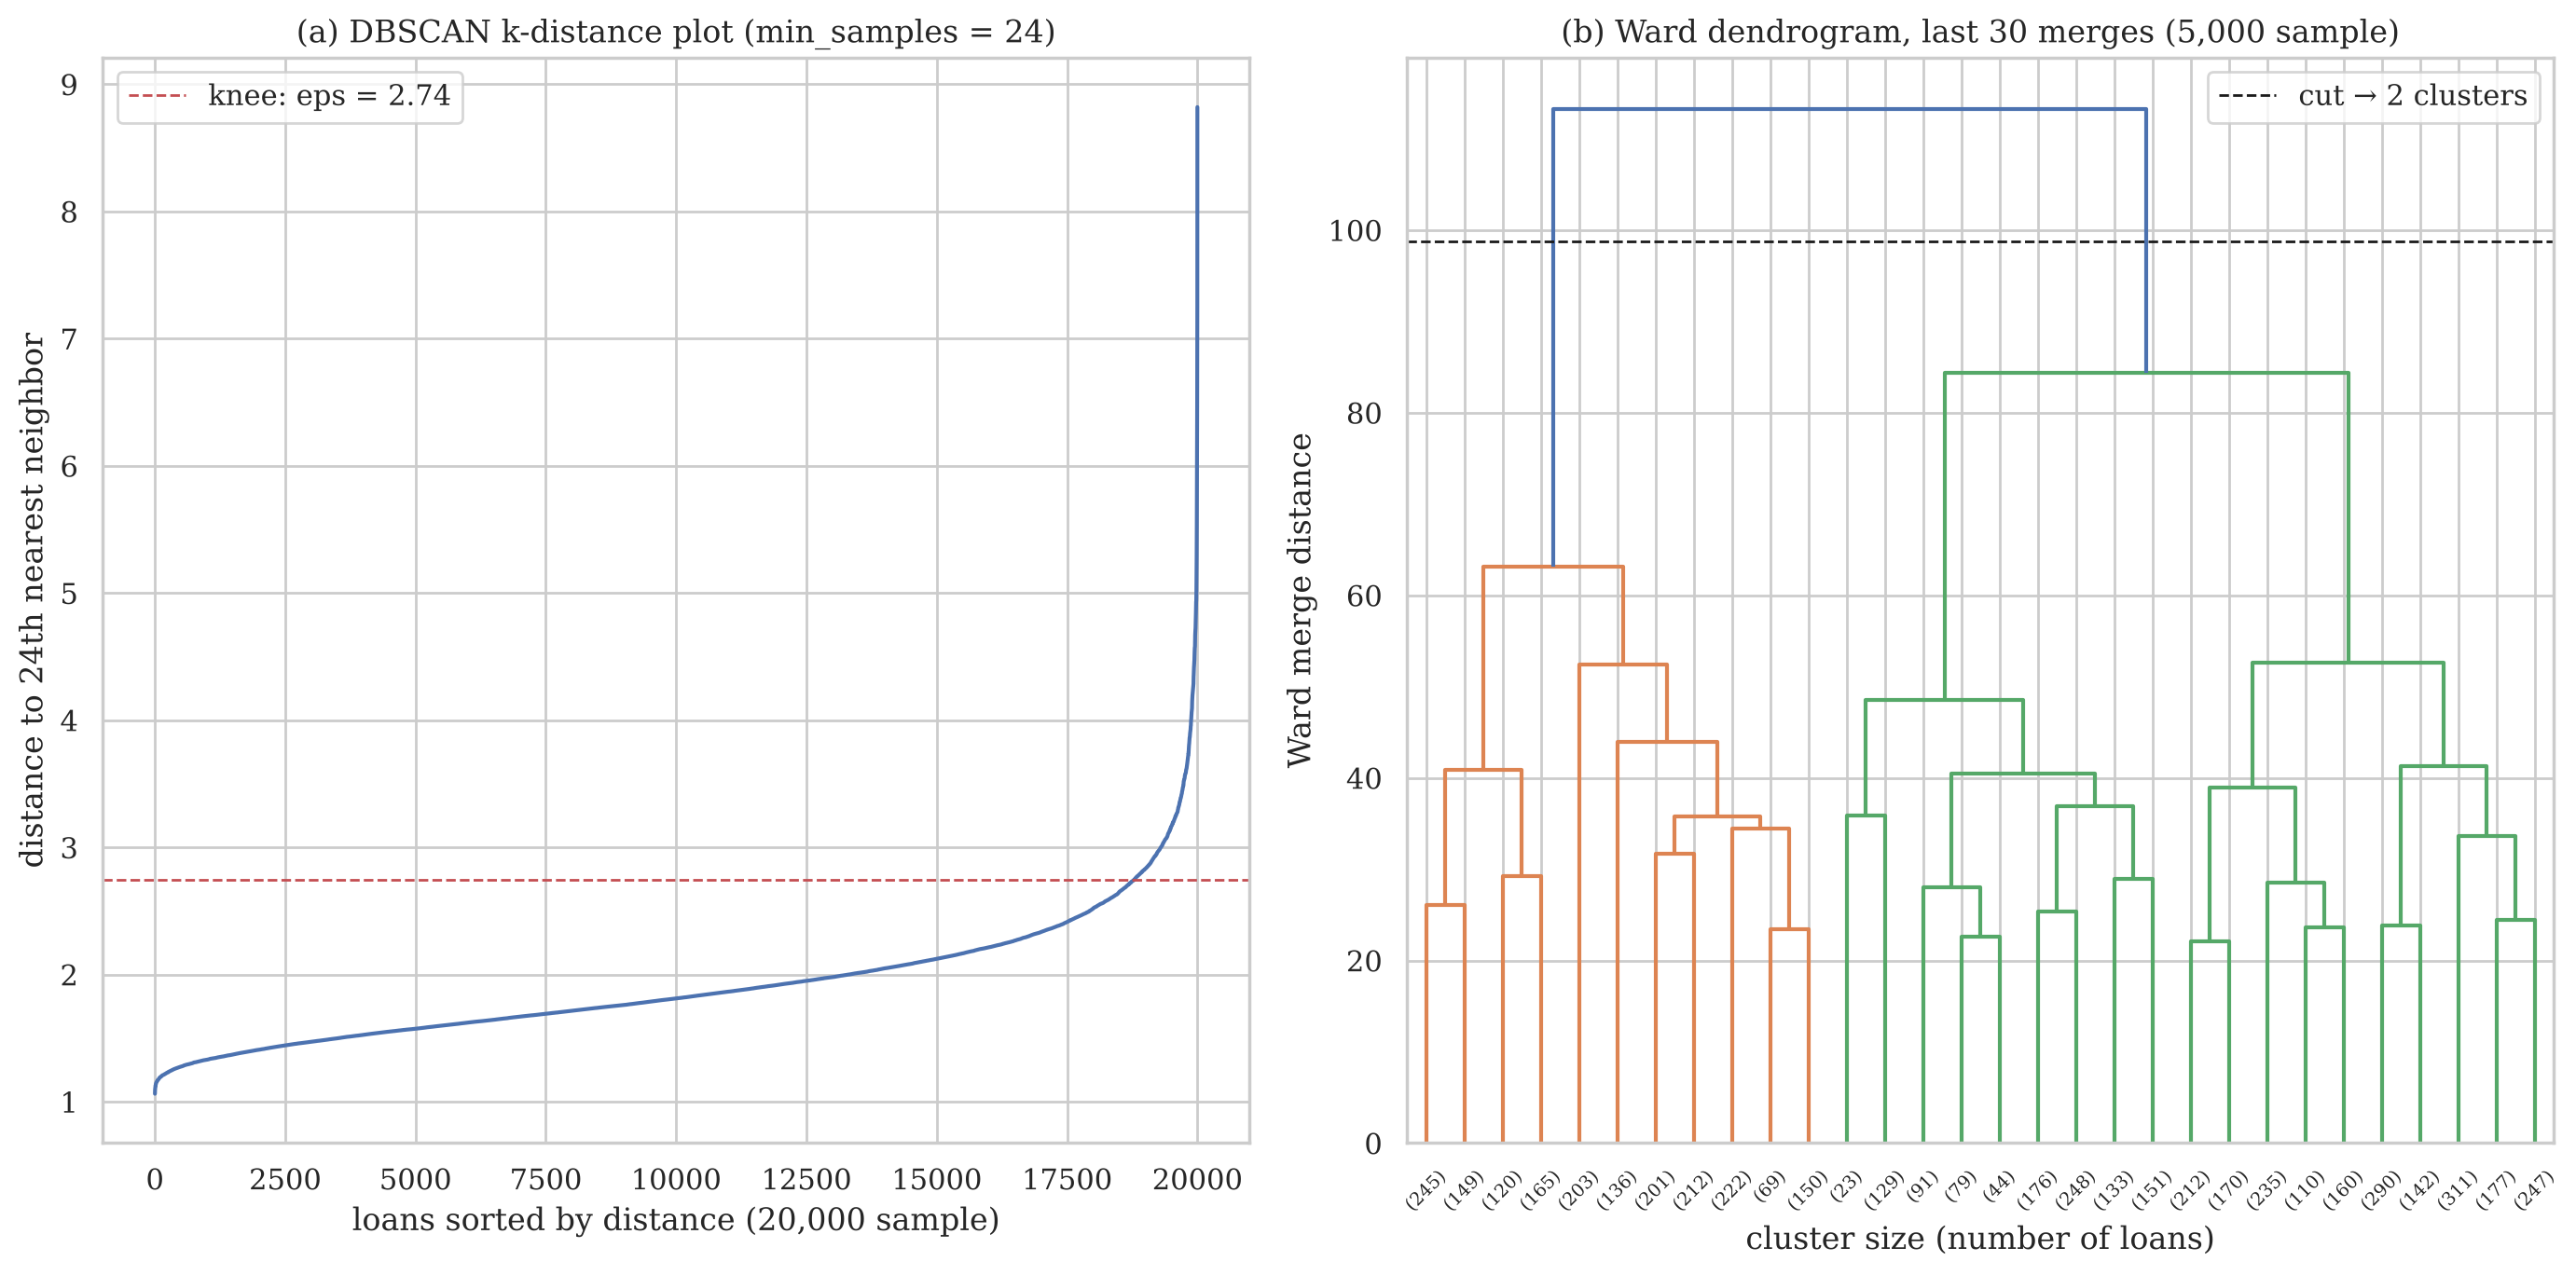

In [10]:
# Figure for the report: (a) DBSCAN k-distance plot, (b) Ward dendrogram (truncated) with the cut
L = links[("ward", "euclidean")]
cut = (L[-K, 2] + L[-K + 1, 2]) / 2      # height between the K-th and (K-1)-th last merges -> K clusters
fig, axes = plt.subplots(1, 2, figsize=(14, 7.0))
axes[0].plot(np.arange(len(kdist)), kdist, lw=1.5)
axes[0].axhline(KNEE_EPS, ls="--", c="#C44E52", lw=1, label=f"knee: eps = {KNEE_EPS:.2f}")
axes[0].set(xlabel=f"loans sorted by distance ({DB_N:,} sample)", ylabel=f"distance to {MIN_SAMPLES}th nearest neighbor",
            title=f"(a) DBSCAN k-distance plot (min_samples = {MIN_SAMPLES})"); axes[0].legend()
dendrogram(L, truncate_mode="lastp", p=30, ax=axes[1], color_threshold=cut, show_leaf_counts=True, leaf_font_size=7)
axes[1].axhline(cut, ls="--", c="k", lw=1, label=f"cut → {K} clusters")
axes[1].set(xlabel="cluster size (number of loans)", ylabel="Ward merge distance", title=f"(b) Ward dendrogram, last 30 merges ({HAC_N:,} sample)")
axes[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_dbscan_hac.png", dpi=200); plt.show()

In [11]:
summary = {"min_samples": MIN_SAMPLES, "knee_eps": KNEE_EPS, "db_clusters": n_clusters, "db_noise_share": noise.mean(),
           "db_largest_share": sizes.max() / len(lab) if n_clusters else 0, "rate_noise": rate_noise, "rate_clustered": rate_core,
           "n_noise": int(noise.sum()), **{f"{m}_{d}_{c}": hac_tab.loc[(m, "manhattan" if d == "cityblock" else d), c]
                                           for (m, d) in links for c in ["ARI vs K-Means", "largest cluster share", "cophenetic corr.", "silhouette"]}}
pd.Series(summary).to_csv(RES_DIR / "week11_summary.csv")
pd.Series(summary)

min_samples                                 24.0000
knee_eps                                     2.7428
db_clusters                                  1.0000
db_noise_share                               0.0149
db_largest_share                             0.9851
rate_noise                                   0.1745
rate_clustered                               0.1459
n_noise                                    298.0000
ward_euclidean_ARI vs K-Means                0.4039
ward_euclidean_largest cluster share         0.6256
ward_euclidean_cophenetic corr.              0.3114
ward_euclidean_silhouette                    0.1204
complete_euclidean_ARI vs K-Means            0.0057
complete_euclidean_largest cluster share     0.9894
complete_euclidean_cophenetic corr.          0.4349
complete_euclidean_silhouette                0.3423
average_euclidean_ARI vs K-Means             0.0003
average_euclidean_largest cluster share      0.9994
average_euclidean_cophenetic corr.           0.6754
average_eucl

## 3. Conclusions

**DBSCAN.** With min_samples = 24 and eps from the k-distance knee (2.74), DBSCAN found one cluster holding 98.5% of the 20,000 sampled loans and labeled 1.5% (298) as noise. Every eps from the 50th to the 98th percentile of the k-distance curve also gave one cluster, with noise falling from 22% to 0.4%. There are no dense, separated borrower groups — consistent with Week 10's low silhouettes.

**Noise loans.** Noise loans are unusual mainly in revolving credit (49% have |z| > 2 on log revolving balance, 41% on utilization) and recent inquiries (34%). Their charge-off rate was 17.4% (52 of 298) vs. 14.6% for clustered loans, but with 298 loans that gap is z = 1.4, not significant. At the strictest eps (98th percentile, 0.4% noise) the rate was 19.3%. DBSCAN is a reasonable outlier screen but not a strong risk signal here.

**Linkage.** On 5,000 loans cut into 2 clusters: average and single linkage (Euclidean or Manhattan) chained almost every loan into one cluster (≥ 99.9%), leaving a few outliers apart. They had the *highest* silhouette (0.54–0.55) and cophenetic correlation (0.61–0.69) — another case where a good index score describes a useless partition. Complete linkage was nearly as unbalanced (98.9%). Ward linkage produced a 63/37 split and agreed with K-Means at ARI 0.40 (85% and 80% of each Ward cluster fell in one K-Means cluster); average linkage on cosine distance gave a similar split (ARI 0.46). Ward is the only Euclidean linkage that matches the K-Means objective, so the agreement is expected; the remaining disagreement reflects how weak the cluster boundaries are.

## Source for this week (shared on Yellowdig)

Schubert, E., Sander, J., Ester, M., Kriegel, H.-P., & Xu, X. (2017). DBSCAN revisited, revisited: Why and how you should (still) use DBSCAN. *ACM Transactions on Database Systems, 42*(3), Article 19. https://doi.org/10.1145/3068335

**Why it is high quality:** Written by DBSCAN's original authors and co-authors in a peer-reviewed journal; it explains the parameters, gives heuristics for choosing eps and min_samples (including the k-distance plot), and warns that when almost everything lands in one cluster or in noise, the parameters or data are unsuitable — exactly what happened here.